# ERA V5 — Session 11 | Optimizer Laboratory
### Adam • bias correction • update-to-weight • cosine vs WSD • LR by width

**Reproducible CPU notebook, grounded in the Session 11 assignment.** The notebook contains its entire executable source; no GitHub clone or internet dataset is needed. All plots and CSV tables are generated from execution rather than mock data.

**Scientific scope:** A small causal residual *token mixer* with synthetic 32-symbol sequences, not a Transformer/production LLM. The 4,096 LR is an explicitly low-confidence extrapolation; no μP is implemented. Hidden validation set has no overlapping full sequences with training.

## Methodology / safeguards

- Hand calculations in `Decimal(precision=55)` vs independent `torch.optim.Adam(float64)` for **all six quantities at five steps**.
- Adam bias correction vs deliberate removal: fixed gradient isolates zero-state bias; report when **individual update size**, not parameter path, stays within 1%/5%.
- Layerwise ratio includes both weight and bias of each parameterized module, before/after snapshots on each update.
- 300-step *planned* schedule, physically **stop at 200**; WSD's cooldown only begins at 241, so it cannot be credited with unobserved improvements.
- Independently LR-tune both schedules with a 120-step two-seed pilot; compare both at step 200 with matched initializations, data, and settings.
- Width sweep covers 256, 512 and 1,024, six LR values, two seeds each; **held-out** cross-entropy selects tested-grid minima.
- Research choices (step counts, rates, seeds, model, data generator) are documented, not passed off as transcript facts.

## 1. Complete source: architecture, independent Adam, schedules and measured experiments

In [1]:
"""ERA V5 Session 11: deterministic Adam, schedules and width-sweep experiments.
Run with python experiment.py. No network or external data dependencies.
All hyperparameters are explicit research choices for this experiment, not from a paper.
"""
from __future__ import annotations
import argparse, csv, json, math, os, platform, random, time
from decimal import Decimal, getcontext
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

OUT = Path(os.environ.get('ERA_S11_OUT',str(Path(__file__).parent if '__file__' in globals() else Path.cwd())))
OUT.mkdir(exist_ok=True,parents=True)
V=32
CONTEXT=12
BATCH=16
WARMUP=20
HORIZON=300
STOP=200
DECAY_START=240
GRADIENTS=[0.4,-0.2,0.1,0.0,-0.3]
LR_GRID=[0.0001,0.0003,0.001,0.003,0.01,0.03]
WIDTHS=[256,512,1024]
SEEDS=[23,47]
EPS=1e-8
B1,B2=0.9,0.999

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

def hand_adam():
    getcontext().prec=55
    d=lambda n:Decimal(str(n))
    b1,b2,eps,lr=d(B1),d(B2),d(EPS),d('0.01')
    m,v,w=d(0),d(0),d('0.7')
    tparam=nn.Parameter(torch.tensor([0.7],dtype=torch.float64))
    opt=torch.optim.Adam([tparam],lr=float(lr),betas=(B1,B2),eps=EPS,weight_decay=0.0,foreach=False)
    rows=[]
    for step,g0 in enumerate(GRADIENTS,1):
        g=d(g0)
        m=b1*m+(1-b1)*g;v=b2*v+(1-b2)*g*g
        mh=m/(1-b1**step);vh=v/(1-b2**step)
        update=lr*mh/(vh.sqrt()+eps);w-=update
        tparam.grad=torch.tensor([g0],dtype=torch.float64)
        old=tparam.item(); opt.step()
        s=opt.state[tparam]
        row={'step':step,'gradient':g0,'m_hand':float(m),'m_torch':s['exp_avg'].item(),
             'v_hand':float(v),'v_torch':s['exp_avg_sq'].item(),
             'mhat_hand':float(mh),'mhat_torch':s['exp_avg'].item()/(1-B1**step),
             'vhat_hand':float(vh),'vhat_torch':s['exp_avg_sq'].item()/(1-B2**step),
             'update_hand':float(update),'update_torch':old-tparam.item(),
             'weight_hand':float(w),'weight_torch':tparam.item()}
        for name in ('m','v','mhat','vhat','update','weight'):
            err=abs(row[f'{name}_hand']-row[f'{name}_torch'])
            assert err<2e-11,(step,name,err)
        rows.append(row)
    return rows

def bias_experiment():
    # Constant gradient isolates initial-zero moment bias; not a learned-model training curve.
    g=0.4;m=v=0.;wcor=wraw=1.;rows=[]
    for t in range(1,16001):
        m=B1*m+(1-B1)*g; v=B2*v+(1-B2)*g*g
        mh=m/(1-B1**t);vh=v/(1-B2**t)
        good=0.001*mh/(math.sqrt(vh)+EPS)
        wrong=0.001*m/(math.sqrt(v)+EPS)
        wcor-=good;wraw-=wrong
        rows.append({'step':t,'correct_step':good,'uncorrected_step':wrong,'correct_weight':wcor,
                     'uncorrected_weight':wraw,'relative_step_difference':abs(wrong/good-1)})
    thresholds={}
    for tol in (0.05,0.01):
        # first point after which every subsequent step through 16000 is inside tolerance
        eligible=[row['step'] for row in rows if row['relative_step_difference']<=tol]
        first_persistent=next((t for t in eligible if all(r['relative_step_difference']<=tol for r in rows[t-1:])),None)
        thresholds[f'{tol:.0%}']=first_persistent
    fig,ax=plt.subplots(figsize=(9,4.4))
    ax.plot([r['step'] for r in rows[:20]],[r['correct_step']/0.001 for r in rows[:20]],marker='o',label='Bias-corrected')
    ax.plot([r['step'] for r in rows[:20]],[r['uncorrected_step']/0.001 for r in rows[:20]],marker='s',label='Bias correction removed')
    ax.set(xlabel='Optimizer step',ylabel='Update magnitude / nominal LR',title='Adam: first 20 updates with and without bias correction')
    ax.legend();ax.grid(alpha=.2);fig.tight_layout();fig.savefig(OUT/'bias_correction_20_steps.png',dpi=160);plt.close(fig)
    return rows[:20],thresholds

def corpus(seed,n,exclude=None):
    """Generate unique stochastic-grammar sequences; held-out data explicitly excludes train examples.
    Note: common generating grammar is intentional; duplicate full sequences are not.
    """
    rng=np.random.default_rng(seed)
    seen=set(exclude or [])
    result=[]
    attempts=0
    while len(result)<n:
        size=max(128,min(4096,2*(n-len(result))))
        tokens=np.zeros((size,CONTEXT+1),dtype=np.int64)
        tokens[:,0]=rng.integers(0,V,size=size)
        for i in range(1,CONTEXT+1):
            prev=tokens[:,i-1]
            r=rng.choice(np.array([0,1,2,3],dtype=np.int64),size=size,p=[0.72,0.15,0.09,0.04])
            tokens[:,i]=(3*prev+(prev%5)+7*i+r)%V
        for row in tokens:
            key=tuple(int(x) for x in row)
            if key not in seen:
                seen.add(key);result.append(row.copy())
                if len(result)==n:break
        attempts+=1
        if attempts>1000:raise RuntimeError('Unable to create disjoint unique corpus')
    return torch.from_numpy(np.stack(result))

TRAIN=corpus(20260905,2048)
VAL=corpus(20269905,512,exclude={tuple(x) for x in TRAIN.tolist()})

def batch_for(step):
    # Identical batch indices across all trials and model widths; no dependence on model RNG.
    rng=np.random.default_rng(1703+step)
    ix=torch.as_tensor(rng.choice(len(TRAIN),size=BATCH,replace=False),dtype=torch.long)
    return TRAIN[ix]

class CausalTokenModel(nn.Module):
    """Small autoregressive causal residual mixer; not a Transformer/attention model.
    Hidden width is swept; bottleneck remains 64. Same architecture otherwise.
    """
    def __init__(self,width):
        super().__init__()
        self.embedding=nn.Embedding(V,width)
        self.position=nn.Embedding(CONTEXT,width)
        self.norm=nn.LayerNorm(width)
        self.ff_in=nn.Linear(width,64)
        self.ff_out=nn.Linear(64,width)
        self.output_head=nn.Linear(width,V)
    def forward(self,x):
        B,T=x.shape
        z=self.embedding(x)+self.position(torch.arange(T,device=x.device))[None,:,:]
        previous=torch.cat([torch.zeros_like(z[:,:1,:]),z[:,:-1,:]],dim=1)
        h=self.norm(z+0.15*previous)
        h=z+self.ff_out(F.gelu(self.ff_in(h)))
        return self.output_head(h)

def full_loss(model,tokens):
    logits=model(tokens[:,:-1])
    return F.cross_entropy(logits.reshape(-1,V),tokens[:,1:].reshape(-1))

@torch.no_grad()
def validation_loss(model):
    model.eval()
    total=0.; n=0
    for b in VAL.split(64):
        loss=full_loss(model,b)
        total+=loss.item()*len(b);n+=len(b)
    model.train();return total/n

def lr_at(step,base,schedule,total=HORIZON,warmup=WARMUP,decay_start=DECAY_START):
    if step<=warmup:
        return base*step/warmup
    if schedule=='cosine':
        f=(step-warmup)/(total-warmup)
        return base*(0.1+0.9*0.5*(1+math.cos(math.pi*f)))
    if schedule=='wsd':
        if step<=decay_start:return base
        f=min(1.,(step-decay_start)/(total-decay_start))
        return base*(1-0.9*f)
    if schedule=='constant':return base
    raise ValueError(schedule)

def param_groups(model):
    return {key:list(mod.parameters(recurse=False)) for key,mod in model.named_modules() if key and list(mod.parameters(recurse=False))}

def run_model(width,lr,schedule,steps,seed,track=False,eval_every=10):
    seed_all(seed)
    model=CausalTokenModel(width)
    groups=param_groups(model)
    optimizer=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=0.01,betas=(B1,B2),eps=EPS,foreach=False)
    hist=[]; layer_log=[];tic=time.perf_counter()
    for t in range(1,steps+1):
        eff_lr=lr_at(t,lr,schedule)
        for group in optimizer.param_groups:group['lr']=eff_lr
        before={name:[p.detach().clone() for p in ps] for name,ps in groups.items()} if track else None
        optimizer.zero_grad(set_to_none=True)
        trainloss=full_loss(model,batch_for(t))
        trainloss.backward()
        optimizer.step()
        if track:
            for name,ps in groups.items():
                x=before[name]
                pnorm=math.sqrt(sum(float(a.square().sum()) for a in x))
                dnorm=math.sqrt(sum(float((p.detach()-a).square().sum()) for p,a in zip(ps,x)))
                layer_log.append({'step':t,'layer':name,'weight_norm_before':pnorm,
                                  'update_norm':dnorm,'update_to_weight':dnorm/max(pnorm,1e-12),'lr':eff_lr})
        if t==1 or t==steps or t%eval_every==0 or t in (WARMUP,WARMUP+1,STOP):
            hist.append({'step':t,'train_batch_loss':float(trainloss.detach()),'val_loss':validation_loss(model),'lr':eff_lr})
    duration=time.perf_counter()-tic
    return {'width':width,'seed':seed,'base_lr':lr,'schedule':schedule,'elapsed_s':duration,
            'parameters':sum(p.numel() for p in model.parameters()),'history':hist,'layers':layer_log,
            'final_val_loss':hist[-1]['val_loss']}

def csvsave(path,rows):
    if not rows: return
    with open(OUT/path,'w',newline='') as f:
        w=csv.DictWriter(f,fieldnames=rows[0].keys());w.writeheader();w.writerows(rows)

def run_all(fast=False):
    torch.set_num_threads(min(2,torch.get_num_threads()))
    t0=time.perf_counter();hand=hand_adam();bias,thresholds=bias_experiment()
    csvsave('adam_hand_vs_pytorch.csv',hand);csvsave('bias_20_steps.csv',bias)
    # Compare truly identical initialization/data, isolating warmup effect in ratio logging.
    warm=run_model(256,0.003,'wsd',30,SEEDS[0],track=True,eval_every=10)
    csvsave('layer_update_ratios.csv',warm['layers'])
    fig,ax=plt.subplots(figsize=(10,4.5))
    for layer in sorted(set(r['layer'] for r in warm['layers'])):
        seq=[r for r in warm['layers'] if r['layer']==layer]
        ax.plot([r['step'] for r in seq],[r['update_to_weight'] for r in seq],label=layer,linewidth=1.4)
    ax.axvline(WARMUP,c='black',ls='--',lw=1,label='Warmup ends (LR plateaus at step 20)')
    ax.set(xlabel='Optimizer step',ylabel='L2(update) / L2(pre-step weights)',title='Observed layerwise update-to-weight ratios')
    ax.legend(ncol=2,fontsize=8);ax.grid(alpha=.2);fig.tight_layout();fig.savefig(OUT/'update_to_weight_ratios.png',dpi=160);plt.close(fig)
    # Independently tune peak LR for each schedule, with equal evaluation protocol.
    lr_grid=LR_GRID if not fast else LR_GRID[:3]
    pilot_steps=120 if not fast else 12
    pilot_seeds=SEEDS if not fast else [SEEDS[0]]
    pilots=[]
    for sched in ('cosine','wsd'):
        for lr in lr_grid:
            for seed in pilot_seeds:
                r=run_model(256,lr,sched,pilot_steps,seed,eval_every=pilot_steps)
                pilots.append({'schedule':sched,'lr':lr,'seed':seed,'val_loss':r['final_val_loss']})
    csvsave('schedule_tuning.csv',pilots)
    means={(s,lr):float(np.mean([r['val_loss'] for r in pilots if r['schedule']==s and r['lr']==lr])) for s in ('cosine','wsd') for lr in lr_grid}
    chosen={s:min(lr_grid,key=lambda lr:(means[(s,lr)],lr)) for s in ('cosine','wsd')}
    final_seeds=SEEDS if not fast else [SEEDS[0]]
    finals={}
    for sched in ('cosine','wsd'):
        finals[sched]=[run_model(256,chosen[sched],sched,STOP if not fast else 30,seed,track=False,eval_every=5) for seed in final_seeds]
    fig,axs=plt.subplots(1,2,figsize=(11,4.25))
    for name,runs in finals.items():
        steps=[p['step'] for p in runs[0]['history']]
        mean_losses=np.mean([[p['val_loss'] for p in r['history']] for r in runs],axis=0)
        axs[0].plot(steps,mean_losses,label=f'{name.upper()} (peak LR={chosen[name]:g}; n={len(runs)})')
        axs[1].plot(range(1,HORIZON+1),[lr_at(t,chosen[name],name) for t in range(1,HORIZON+1)],label=name.upper())
    axs[0].set(xlabel='Optimizer steps completed',ylabel='Held-out cross entropy',title='Stopped at step 200 of planned 300')
    axs[1].axvline(STOP,c='black',ls='--',lw=1,label='Stopped at 200')
    axs[1].axvline(DECAY_START,c='gray',ls=':',lw=1,label='WSD decay would start at 240')
    axs[1].set(xlabel='Step of planned 300-step schedule',ylabel='Learning rate',title='Learning-rate schedules (future steps only planned)')
    for ax in axs:ax.legend(fontsize=8);ax.grid(alpha=.2)
    fig.tight_layout();fig.savefig(OUT/'cosine_vs_wsd_stop200.png',dpi=160);plt.close(fig)
    csvsave('schedule_final_histories.csv',[{'schedule':s,'seed':r['seed'],**v} for s,runs in finals.items() for r in runs for v in r['history']])
    # Width sweep: controlled recipe, same loss evaluation, repeated seeds.
    sweep_steps=55 if not fast else 8
    sweep_seeds=SEEDS if not fast else [SEEDS[0]]
    sweep=[]
    for width in WIDTHS:
        for lr in lr_grid:
            for seed in sweep_seeds:
                r=run_model(width,lr,'constant',sweep_steps,seed,eval_every=sweep_steps)
                sweep.append({'width':width,'lr':lr,'seed':seed,'val_loss':r['final_val_loss'],
                              'parameters':r['parameters'],'seconds':r['elapsed_s']})
    csvsave('width_lr_sweep.csv',sweep)
    vals={w:{lr:float(np.mean([x['val_loss'] for x in sweep if x['width']==w and x['lr']==lr])) for lr in lr_grid} for w in WIDTHS}
    winners={w:min(lr_grid,key=lambda lr:(vals[w][lr],lr)) for w in WIDTHS}
    fig,ax=plt.subplots(figsize=(9,5))
    for w in WIDTHS:
        x=np.array(lr_grid);y=np.array([vals[w][lr] for lr in lr_grid])
        ax.semilogx(x,y,marker='o',label=f'width {w}')
        ax.scatter([winners[w]],[vals[w][winners[w]]],marker='*',s=180,zorder=3)
        ax.annotate(f'min {winners[w]:g}',(winners[w],vals[w][winners[w]]),xytext=(4,-13),textcoords='offset points',fontsize=8)
    ax.set(xlabel='Peak/base learning rate (log scale)',ylabel='Mean held-out cross entropy across seeds',
           title='Standard-parameterized width sweep — measured grid minima only')
    ax.legend();ax.grid(alpha=.2);fig.tight_layout();fig.savefig(OUT/'lr_sweep_widths.png',dpi=160);plt.close(fig)
    # Conservative decision: if stable across widths select last observed grid winner; not a muTransfer claim.
    all_same=len(set(winners.values()))==1
    choice=winners[1024]
    final_loss_mean={s:float(np.mean([r['final_val_loss'] for r in runs])) for s,runs in finals.items()}
    winner_sched=min(finals,key=lambda s:(final_loss_mean[s],s))
    summary={'environment':{'torch':torch.__version__,'device':'cpu','cpu_threads':torch.get_num_threads(),
               'platform':platform.platform()},'experiment':{'vocab':V,'context':CONTEXT,'batch':BATCH,
               'train_examples':len(TRAIN),'heldout_examples':len(VAL),'seed':SEEDS[0],
               'sweep_seeds':sweep_seeds,'pilot_seeds':pilot_seeds,
               'architecture':'causal residual token mixer, not Transformer, standard parameterization',
               'optimizer':'AdamW, betas=(0.9,0.999), eps=1e-8, decoupled weight decay=0.01 for model only',
               'warmup':WARMUP,'planned_steps':HORIZON,'stop_steps':STOP,'wsd_decay_start':DECAY_START,
               'lr_grid':lr_grid,'pilot_steps':pilot_steps,'width_sweep_steps':sweep_steps},
               'adam':{'five_gradients':GRADIENTS,'start_weight':0.7,'max_abs_error':max(abs(r[k+'_hand']-r[k+'_torch']) for r in hand for k in ('m','v','mhat','vhat','update','weight')),
                       'final_weight':hand[-1]['weight_hand']},
               'bias_correction':{'thresholds_for_persistent_relative_per_step_update_difference':thresholds,
                    'step_1_relative_difference':bias[0]['relative_step_difference'],
                    'step_20_relative_difference':bias[-1]['relative_step_difference'],
                    'criterion':'constant 0.4 gradient, relative update not accumulated parameter gap'},
               'warmup':{'ends_at_optimizer_step':WARMUP,'lr_plateau_starts':WARMUP+1,
                         'note':'ratio does not necessarily flatten when warmup ends'},
               'schedules':{'pilot_mean_loss':{s:{str(lr):means[(s,lr)] for lr in lr_grid} for s in ('cosine','wsd')},
                            'independent_best_lr':chosen,
                            'step200_mean_val_loss':final_loss_mean,
                            'step200_val_loss_by_seed':{s:{str(r['seed']):r['final_val_loss'] for r in runs} for s,runs in finals.items()},
                            'would_keep_at_step200':winner_sched,
                            'caveat':'WSD decay planned at step 240 and therefore not yet observed at stop 200'},
               'width_sweep':{'minima_on_tested_grid':{str(w):{'lr':winners[w],'mean_val_loss':vals[w][winners[w]]} for w in WIDTHS},
                              'candidate_at_4096':choice,'confidence':'very low',
                              'same_grid_winner_all_widths':all_same,
                              'caveat':'standard PyTorch parameterization; no μP nor zero-shot μTransfer validated'},
               'elapsed_seconds':time.perf_counter()-t0,
               'fast_smoke_test':fast}
    (OUT/'results.json').write_text(json.dumps(summary,indent=2))
    print(json.dumps({'adam_max_error':summary['adam']['max_abs_error'],
                      'bias_thresholds':thresholds,'selected_schedule':winner_sched,
                      'schedule_losses':summary['schedules']['step200_mean_val_loss'],
                      'width_minima':summary['width_sweep']['minima_on_tested_grid'],
                      '4096_candidate':choice,'seconds':summary['elapsed_seconds']},indent=2))
    return summary



## 2. Verify disjoint training/held-out data and causal behavior

In [2]:
print('TRAIN:',tuple(TRAIN.shape),'VALID:',tuple(VAL.shape))
assert not {tuple(x) for x in TRAIN.tolist()} & {tuple(x) for x in VAL.tolist()}
seed_all(23)
causal_model = CausalTokenModel(256)
x=TRAIN[:2,:-1].clone(); original=causal_model(x)
x[:,5:]=(x[:,5:]+13)%V
revised=causal_model(x)
assert torch.allclose(original[:,:5],revised[:,:5],rtol=1e-6,atol=1e-6)
print('PASS: no full-sequence duplicates; modifying future tokens does not change earlier logits')

TRAIN: (2048, 13) VALID: (512, 13)
PASS: no full-sequence duplicates; modifying future tokens does not change earlier logits


## 3. Hand-computed Adam compared with `torch.optim.Adam`

In [3]:
adam_rows = hand_adam()
print('step | grad | m | v | m-hat | v-hat | signed update | weight')
for r in adam_rows:
 print(f"{r['step']:>4} | {r['gradient']:+.3f} | {r['m_hand']:+.9f} | {r['v_hand']:.9f} | {r['mhat_hand']:+.9f} | {r['vhat_hand']:.9f} | {r['update_hand']:+.9f} | {r['weight_hand']:.9f}")
print('PASS: all six columns × five steps verified independently')

step | grad | m | v | m-hat | v-hat | signed update | weight
   1 | +0.400 | +0.040000000 | 0.000160000 | +0.400000000 | 0.160000000 | +0.010000000 | 0.690000000
   2 | -0.200 | +0.016000000 | 0.000199840 | +0.084210526 | 0.099969985 | +0.002663370 | 0.687336630
   3 | +0.100 | +0.024400000 | 0.000209640 | +0.090036900 | 0.069949980 | +0.003404291 | 0.683932339
   4 | +0.000 | +0.021960000 | 0.000209431 | +0.063855772 | 0.052436232 | +0.002788588 | 0.681143750
   5 | -0.300 | -0.010236000 | 0.000299221 | -0.024995727 | 0.059964026 | -0.001020752 | 0.682164503
PASS: all six columns × five steps verified independently


## 4. Run full experiment (may take tens of seconds on a CPU)

All measurements are logged and plots saved. `run_all()` deliberately regenerates outputs; no stale results are carried forward.

In [4]:
summary=run_all(fast=False)
assert not summary['fast_smoke_test']
print('Planned 300, stopped at',summary['experiment']['stop_steps'])
print('Selected pilot LRs:',summary['schedules']['independent_best_lr'])
print('Held-out losses at 200:',summary['schedules']['step200_mean_val_loss'])
print('Width grid minima:',summary['width_sweep']['minima_on_tested_grid'])
print('4096 provisional LR:',summary['width_sweep']['candidate_at_4096'], 'confidence:',summary['width_sweep']['confidence'])

{
  "adam_max_error": 1.457167719820518e-15,
  "bias_thresholds": {
    "5%": 2375,
    "1%": 3925
  },
  "selected_schedule": "cosine",
  "schedule_losses": {
    "cosine": 1.0818560048937798,
    "wsd": 1.1635027527809143
  },
  "width_minima": {
    "256": {
      "lr": 0.01,
      "mean_val_loss": 1.6267360523343086
    },
    "512": {
      "lr": 0.003,
      "mean_val_loss": 1.7944588884711266
    },
    "1024": {
      "lr": 0.003,
      "mean_val_loss": 1.7396743074059486
    }
  },
  "4096_candidate": 0.003,
  "seconds": 21.171752209000033
}
Planned 300, stopped at 200
Selected pilot LRs: {'cosine': 0.003, 'wsd': 0.003}
Held-out losses at 200: {'cosine': 1.0818560048937798, 'wsd': 1.1635027527809143}
Width grid minima: {'256': {'lr': 0.01, 'mean_val_loss': 1.6267360523343086}, '512': {'lr': 0.003, 'mean_val_loss': 1.7944588884711266}, '1024': {'lr': 0.003, 'mean_val_loss': 1.7396743074059486}}
4096 provisional LR: 0.003 confidence: very low


## 5. Bias correction, layerwise warmup ratios, schedule comparison, width grid

Measured plot: bias_correction_20_steps.png


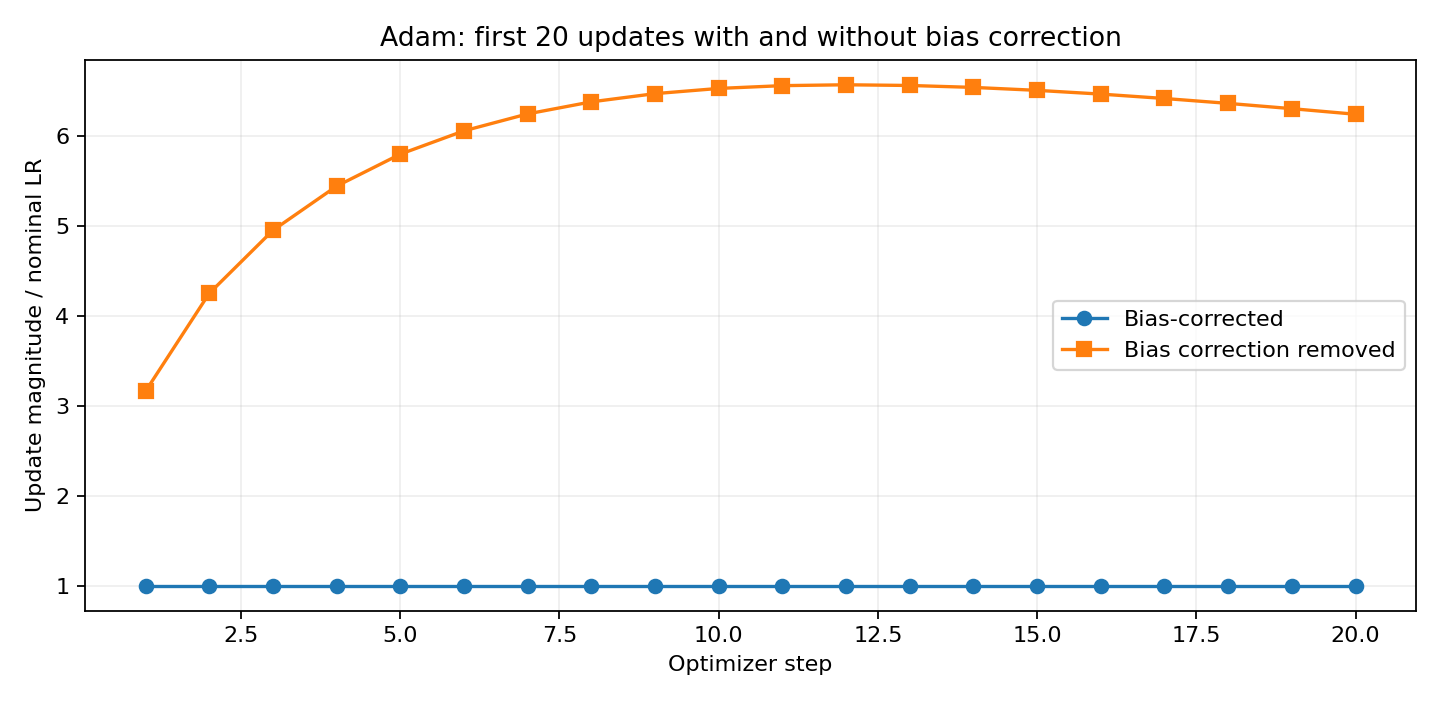

Measured plot: update_to_weight_ratios.png


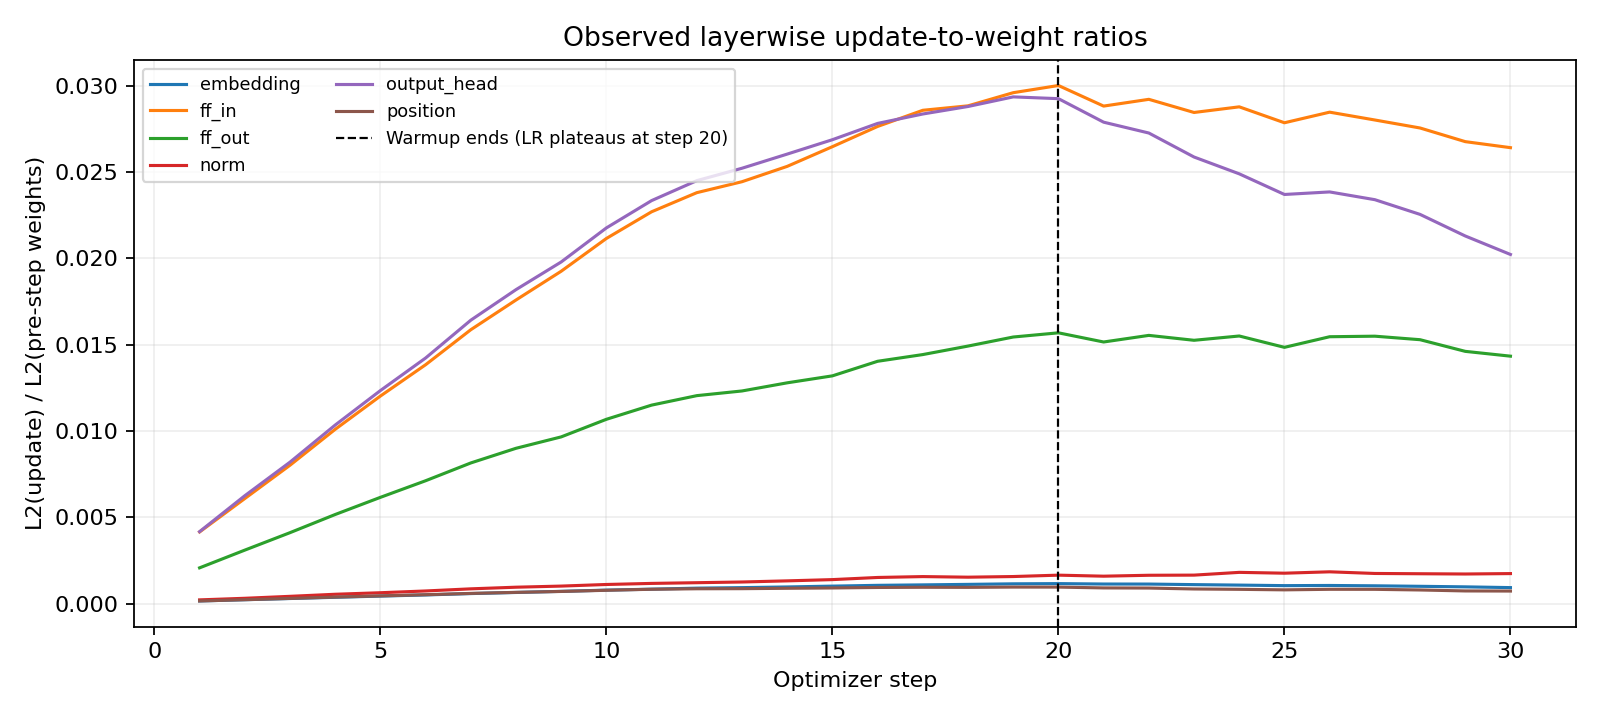

Measured plot: cosine_vs_wsd_stop200.png


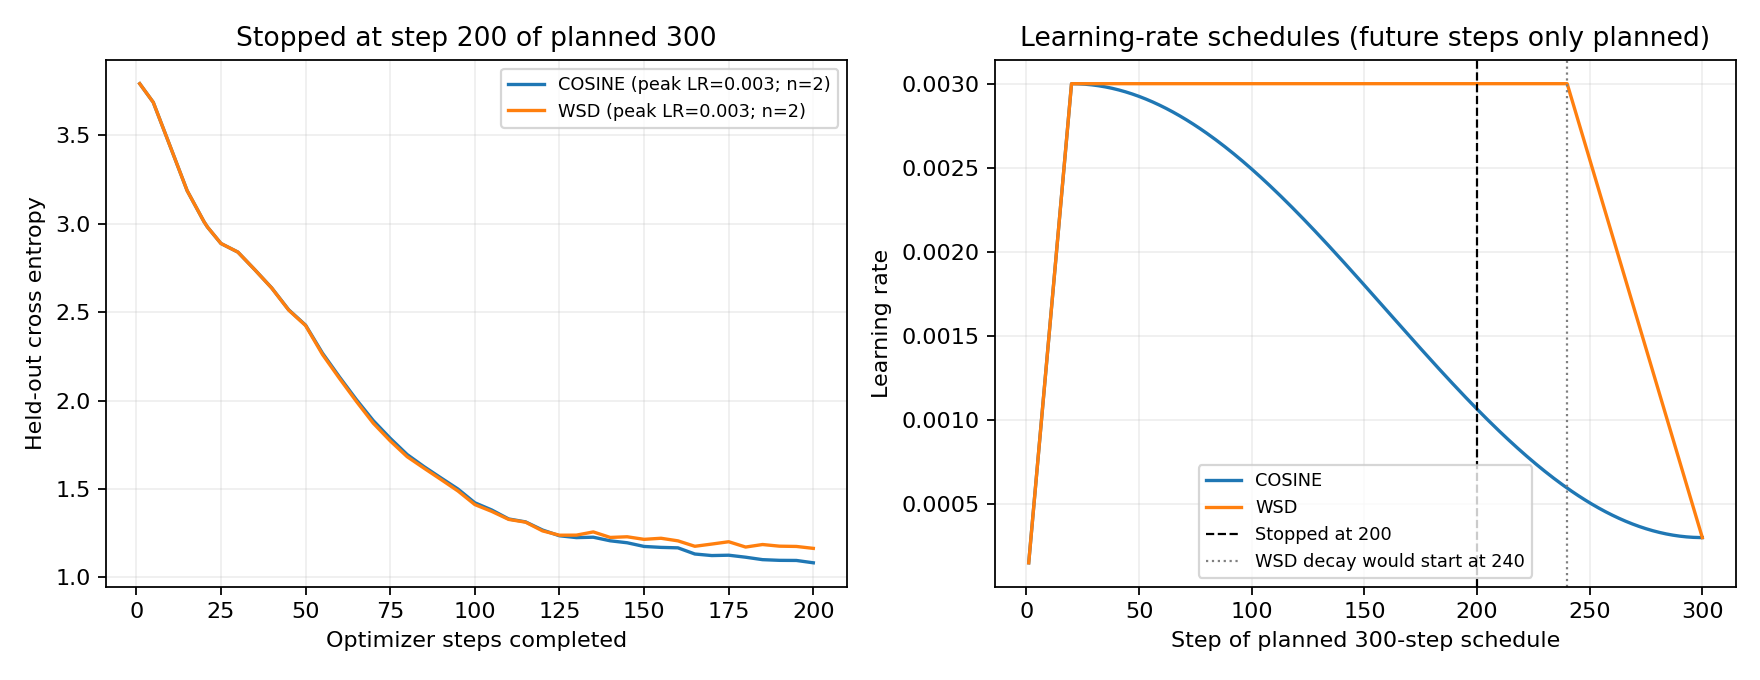

Measured plot: lr_sweep_widths.png


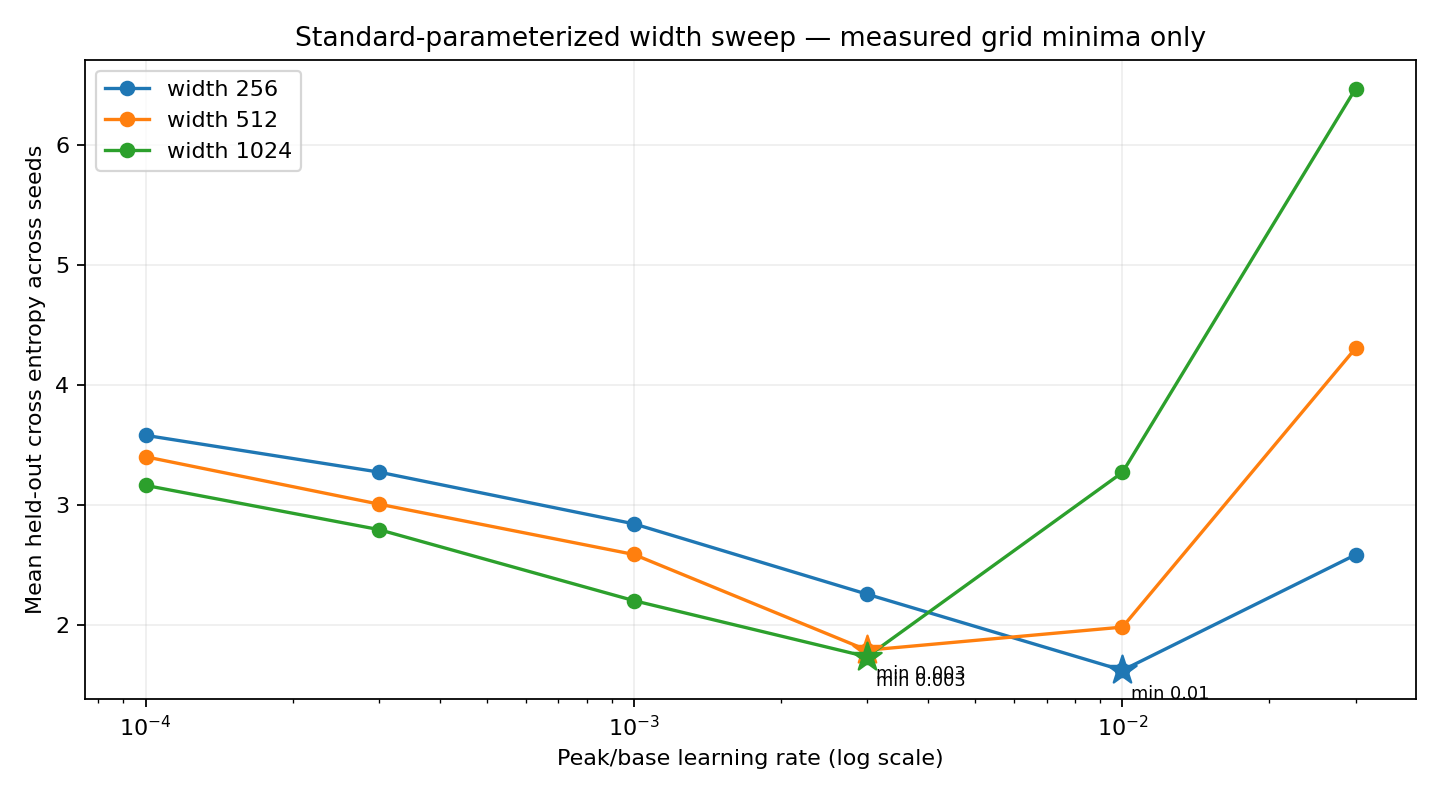

In [5]:
from IPython.display import Image, display
for img in ['bias_correction_20_steps.png','update_to_weight_ratios.png','cosine_vs_wsd_stop200.png','lr_sweep_widths.png']:
    print('Measured plot:',img)
    display(Image(filename=str(OUT/img),width=880))

## 6. Interpret the numbers (without exaggeration)

- Bias correction is **not** AdamW weight decay. `m̂` and `v̂` correct zero-initialized EMAs; AdamW's decoupling is different.
- At **step 21**, scheduled WSD warmup stops increasing the learning rate. The update-to-weight ratios still vary with optimizer state and gradients.
- At step 200, WSD has **not** entered its planned decay. Keep whichever checkpoint has lower held-out loss **at 200**, without asserting that it wins at the full schedule horizon.
- Width 4,096 was **not run**. A provisional starting LR from ordinary PyTorch width scaling is not established μTransfer. Test it before use.

### Primary references

- [PyTorch Adam specification](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html)
- [Adam](https://arxiv.org/abs/1412.6980) and [AdamW](https://arxiv.org/abs/1711.05101)
- [MiniCPM WSD](https://arxiv.org/abs/2404.06395) and [WSD analysis](https://arxiv.org/abs/2410.05192)
- [Tensor Programs V / μTransfer](https://arxiv.org/abs/2203.03466)

Refer to `README.md`, `WRITEUP.md`, and `ACCURACY_AUDIT.md` in the ZIP for complete detail and original code checks.